# PPP Training Log Tracker

Parse PatchPerPix experiment `run.log` files into a DataFrame and overlay train loss
(`PatchPerPix/experiments/ppp_train_track.py`).

## Data sources

Primary: `metrics/ppp/<exp_id>/run.log` (appended across SLURM resumes, so early
iterations are retained).

| Label | Path | Approx. coverage |
|-------|------|------------------|
| `basic_8h` | `metrics/ppp/ppp_basic_8h/run.log` | iters 1–8700 |
| `fmaps24` | `metrics/ppp/ppp_basic_fmaps24/run.log` | iters 1–80000 |
| `long8h` | `metrics/ppp/ppp_basic_long8h/run.log` | iters 1–80000 |

Fallback (not used here): `sbatch/ppp/*_train*.out` — often only the latest resume
segment (e.g. fmaps24 train `.out` starts near iteration 40001).

TensorBoard event files are not available for these runs (`tensorboard` /
`tensorboardX` were not installed in the overlay), so only the gunpowder stdout
scalars `iteration` / `loss` / `time` are parsed. No val curve in these text logs.

## Processing

1. Regex-extract `Train process: iteration=N loss=X time=Y` lines.
2. Deduplicate by `iteration`, keeping the **last** occurrence (resume appends).
3. Sort by `iteration` ascending.
4. Add `loss_smooth` = rolling mean (window 100, centered) for plotting; raw `loss` kept.

In [1]:
import os
import sys
from pathlib import Path

root = Path.cwd()
if root.name == "ipynb":
    root = root.parent
    os.chdir(root)
print(root)

experiments = root / "PatchPerPix" / "experiments"
if str(experiments) not in sys.path:
    sys.path.insert(0, str(experiments))

import matplotlib.pyplot as plt
import pandas as pd

from ppp_train_track import load_ppp_runs, plot_train_loss

/scratch/wmz2007/neuroinfo_fruitfly


## Config

Point `RUNS` at `run.log` paths under `metrics/ppp/`.

In [2]:
RUNS = {
    "fmaps24_80k": "metrics/ppp/ppp_basic_fmaps24/run.log",
    "fmaps24_400k": "metrics/ppp/ppp_basic_fmaps24_400k/run.log",
    "noenc": "metrics/ppp/basic-ppp-noenc/run.log",
}
SMOOTH_WINDOW = 1000

## Load

In [3]:
df = load_ppp_runs(RUNS, smooth_window=SMOOTH_WINDOW)

summary = (
    df.groupby("run", sort=False)
    .agg(
        n_iters=("iteration", "count"),
        iter_min=("iteration", "min"),
        iter_max=("iteration", "max"),
        loss_mean=("loss", "mean"),
    )
)
print(summary.to_string())
df.groupby("run", sort=False).head(3)

              n_iters  iter_min  iter_max  loss_mean
run                                                 
fmaps24_80k     80000         1     80000   0.033780
fmaps24_400k   400002         1    400002   0.020659
noenc           31498         1     31498   0.021212


,run,iteration,loss,time,loss_smooth
0,fmaps24_80k,1,1.750320,11.861,0.375231
1,fmaps24_80k,2,1.454347,25.036,0.374655
2,fmaps24_80k,3,1.523493,0.302,0.373994
80000,fmaps24_400k,1,1.855873,11.619,0.318456
80001,fmaps24_400k,2,1.721653,25.063,0.317867
80002,fmaps24_400k,3,1.687688,0.302,0.317269
480002,noenc,1,1.711071,75.548,0.154091
480003,noenc,2,1.107205,33.796,0.153894
480004,noenc,3,0.887262,3.049,0.153635


In [4]:
df = df[df['iteration'] > 1000]

## Plot (smoothed loss)

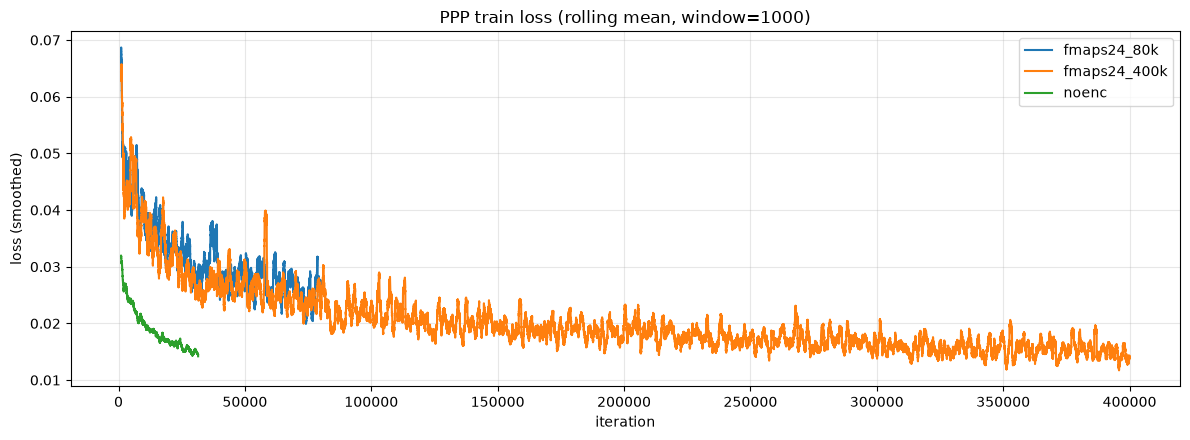

In [5]:
ax = plot_train_loss(
    df,
    use_smooth=True,
    title=f"PPP train loss (rolling mean, window={SMOOTH_WINDOW})",
)
plt.show()

## Optional: raw loss (sanity check)

Per-iteration loss is noisy; use a low alpha overlay if you want to see the raw series.

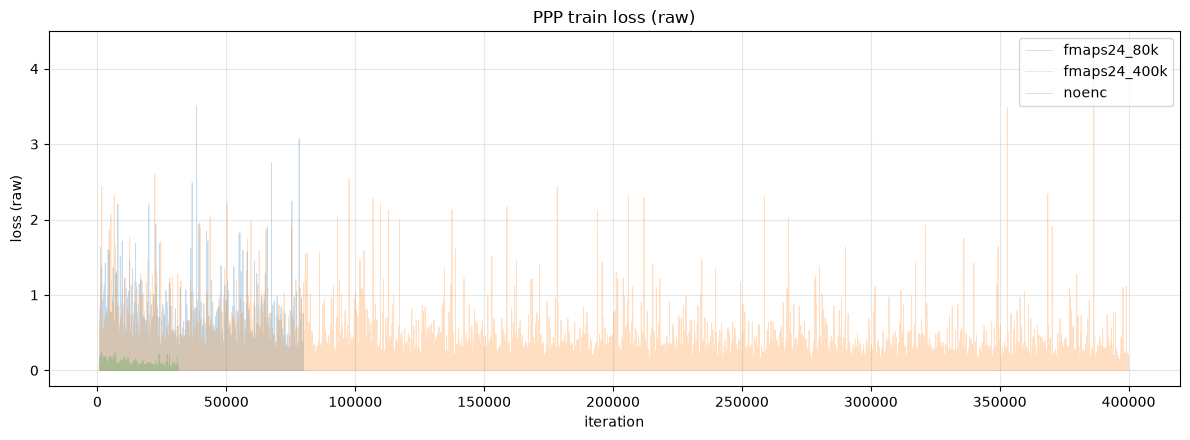

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for run_name, group in df.groupby("run", sort=False):
    ax.plot(
        group["iteration"],
        group["loss"],
        label=run_name,
        alpha=0.25,
        linewidth=0.6,
    )
ax.set_xlabel("iteration")
ax.set_ylabel("loss (raw)")
ax.set_title("PPP train loss (raw)")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()